### Step:Import required libarires

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Split the dataset
from sklearn.model_selection import train_test_split

# Handle missing values
from sklearn.impute import SimpleImputer

# Encode categorical variables
from sklearn.preprocessing import OneHotEncoder

# Preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

### Step 2:Load datasets

In [4]:
df = pd.read_csv(r"C:\Users\Avadhut\Downloads\perf_train.csv")

In [5]:
df

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,11996,49.0,Female,Kolkata,Post Graduate,NaN,16.7,85567.0,20.0,233.0,...,2.0,4.6,7.0,48.0,4.0,4.0,Average,6.7,24.0,Average Performer
1996,11997,26.0,Male,Bengaluru,NaN,Sales,2.1,80713.0,29.0,34.0,...,3.0,NaN,4.0,63.0,11.0,3.0,Poor,0.3,24.0,Low Performer
1997,11998,NaN,NaN,Hyderabad,Diploma,Sales,2.5,76639.0,NaN,27.0,...,2.0,2.4,65.0,NaN,11.0,5.0,Good,6.6,8.0,Low Performer
1998,11999,49.0,Male,Bengaluru,Graduate,Finance,1.1,121603.0,5.0,9.0,...,NaN,3.2,72.0,131.0,10.0,5.0,Average,7.2,17.0,Low Performer


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2000
Number of columns: 22


### Step 3:Understand the data

In [7]:
print(df.columns.tolist())

['Employee_ID', 'Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days', 'Performance_Category']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           2000 non-null   int64  
 1   Age                   1873 non-null   float64
 2   Gender                1934 non-null   object 
 3   City                  1789 non-null   object 
 4   Education_Level       1806 non-null   object 
 5   Department            1801 non-null   object 
 6   Experience_Years      1747 non-null   float64
 7   Monthly_Salary        1895 non-null   float64
 8   Projects_Completed    1712 non-null   float64
 9   Training_Hours        1702 non-null   float64
 10  Certifications        1695 non-null   float64
 11  Work_Life_Balance     1819 non-null   float64
 12  Job_Satisfaction      1804 non-null   float64
 13  Manager_Rating        1853 non-null   float64
 14  Overtime_Hours        1810 non-null   float64
 15  Commute_Time_Min     

In [9]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Employee_ID,2000.0,11000.500000,577.494589,10001.0,10500.75,11000.5,11500.25,12000.0
Age,1873.0,39.294180,10.853357,21.0,30.00,40.0,49.00,57.0
Experience_Years,1747.0,9.351116,5.079696,0.5,5.00,9.3,13.80,18.0
Monthly_Salary,1895.0,82924.088654,38210.918035,18018.0,50205.50,81830.0,116175.50,149960.0
Projects_Completed,1712.0,20.056659,11.279757,1.0,10.00,20.0,30.00,39.0
Training_Hours,1702.0,150.835488,85.021787,5.0,80.00,148.5,224.00,299.0
Certifications,1695.0,2.555162,1.697382,0.0,1.00,3.0,4.00,5.0
Work_Life_Balance,1819.0,3.055525,1.454743,1.0,2.00,3.0,4.00,5.0
Job_Satisfaction,1804.0,3.006098,1.402188,1.0,2.00,3.0,4.00,5.0
Manager_Rating,1853.0,3.490070,0.848336,2.0,2.80,3.5,4.20,5.0


In [10]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee_ID,2000.0,NaN,NaN,NaN,11000.5,577.494589,10001.0,10500.75,11000.5,11500.25,12000.0
Age,1873.0,NaN,NaN,NaN,39.29418,10.853357,21.0,30.0,40.0,49.0,57.0
Gender,1934,3,Male,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1789,7,Delhi,294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,1806,4,Graduate,841,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,1801,6,Sales,323,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Experience_Years,1747.0,NaN,NaN,NaN,9.351116,5.079696,0.5,5.0,9.3,13.8,18.0
Monthly_Salary,1895.0,NaN,NaN,NaN,82924.088654,38210.918035,18018.0,50205.5,81830.0,116175.5,149960.0
Projects_Completed,1712.0,NaN,NaN,NaN,20.056659,11.279757,1.0,10.0,20.0,30.0,39.0
Training_Hours,1702.0,NaN,NaN,NaN,150.835488,85.021787,5.0,80.0,148.5,224.0,299.0


In [11]:
#checking the duplicates
print("Duplicate rows:", df.duplicated().sum())
print(
    "Duplicate employee IDs:",
    df["Employee_ID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate employee IDs: 0


### Step 4:Finding the missing values

In [12]:
missing_count = df.isnull().sum()

print(missing_count)

Employee_ID               0
Age                     127
Gender                   66
City                    211
Education_Level         194
Department              199
Experience_Years        253
Monthly_Salary          105
Projects_Completed      288
Training_Hours          298
Certifications          305
Work_Life_Balance       181
Job_Satisfaction        196
Manager_Rating          147
Overtime_Hours          190
Commute_Time_Min        195
Laptop_Issue_Count       67
Cafeteria_Rating        283
Internet_Stability      343
Last_Promotion_Years    164
Absenteeism_Days        319
Performance_Category      0
dtype: int64


In [13]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
Internet_Stability,343,17.15
Absenteeism_Days,319,15.95
Certifications,305,15.25
Training_Hours,298,14.90
Projects_Completed,288,14.40
Cafeteria_Rating,283,14.15
Experience_Years,253,12.65
City,211,10.55
Department,199,9.95
Job_Satisfaction,196,9.80


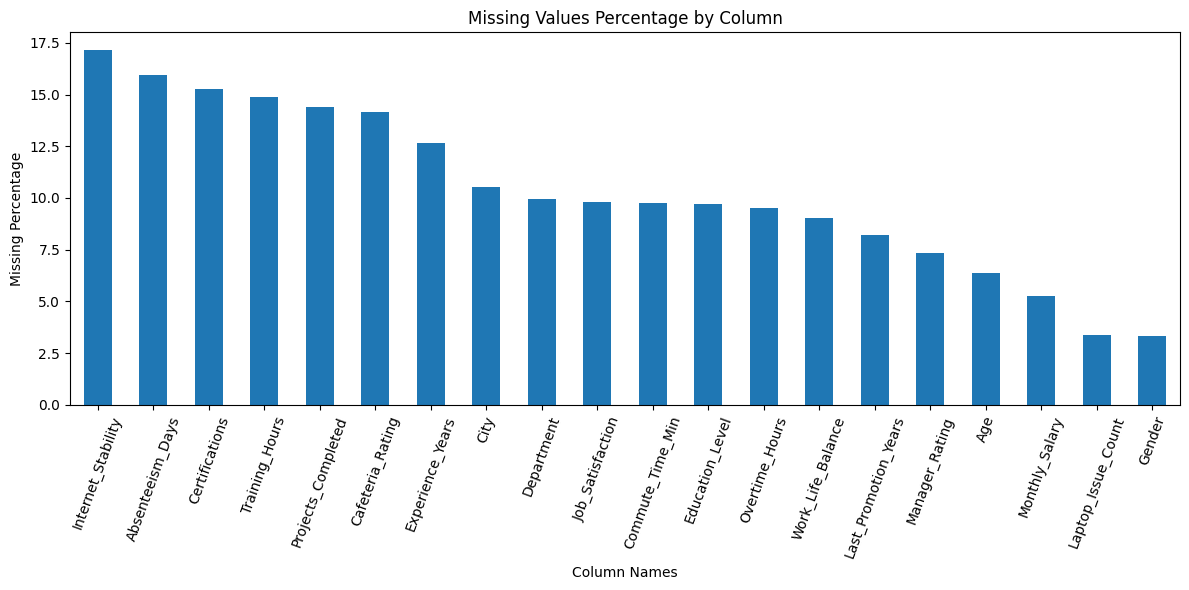

In [15]:
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[
    missing_percent > 0
]

plt.figure(figsize=(12, 6))

missing_percent.plot(kind="bar")

plt.title("Missing Values Percentage by Column")
plt.xlabel("Column Names")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

In [16]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Employee_ID', 'Age', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Last_Promotion_Years', 'Absenteeism_Days']

Categorical columns:
['Gender', 'City', 'Education_Level', 'Department', 'Internet_Stability', 'Performance_Category']


### Step 5: Check duplicate records and unusual values

In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
#Use boxplots to inspect potential outliers

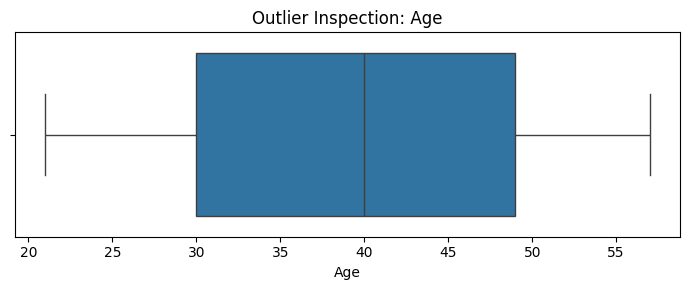

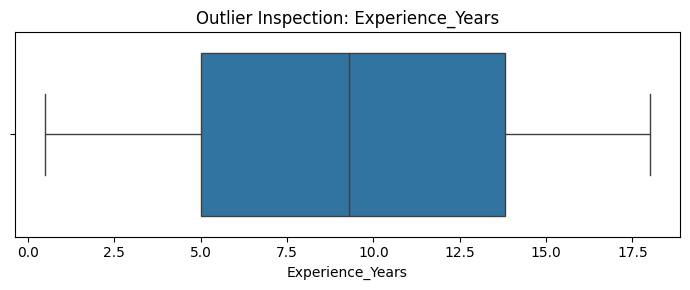

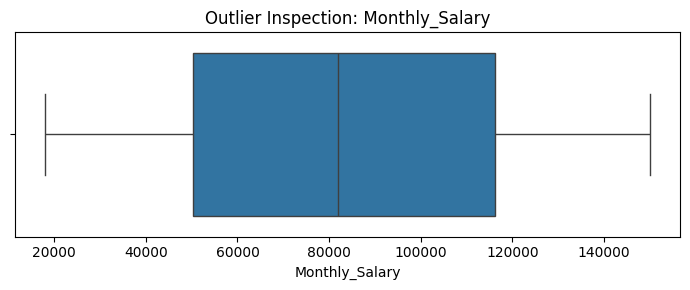

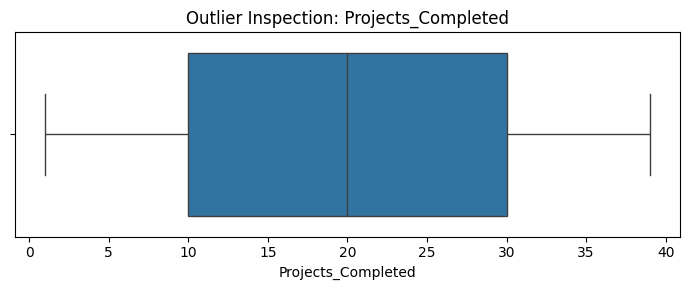

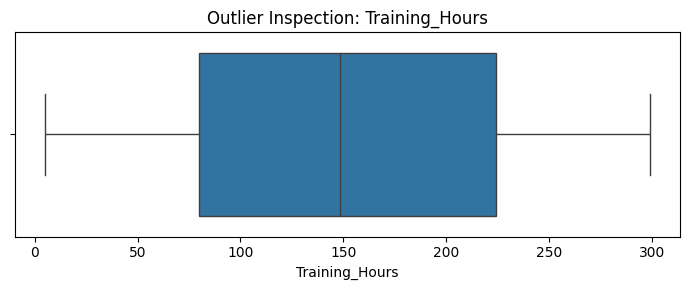

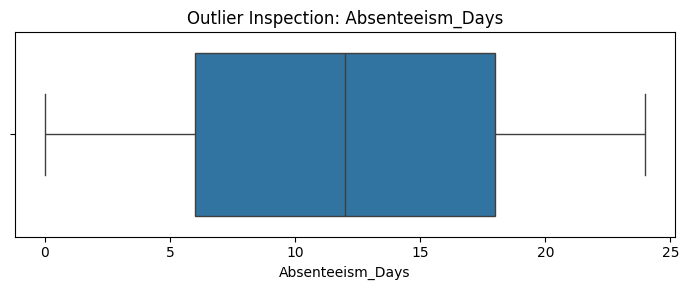

In [19]:
important_numeric = [
    "Age",
    "Experience_Years",
    "Monthly_Salary",
    "Projects_Completed",
    "Training_Hours",
    "Absenteeism_Days"
]

for column in important_numeric:

    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Inspection: {column}")
    plt.tight_layout()
    plt.show()

### Step 6: Explore the target variable

In [20]:
print(df["Performance_Category"].value_counts())

Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64


In [21]:
#Calculate the percentages
class_percentage = (
    df["Performance_Category"]
    .value_counts(normalize=True) * 100
).round(2)

print(class_percentage)

Performance_Category
Average Performer    56.45
Low Performer        33.15
High Performer       10.40
Name: proportion, dtype: float64


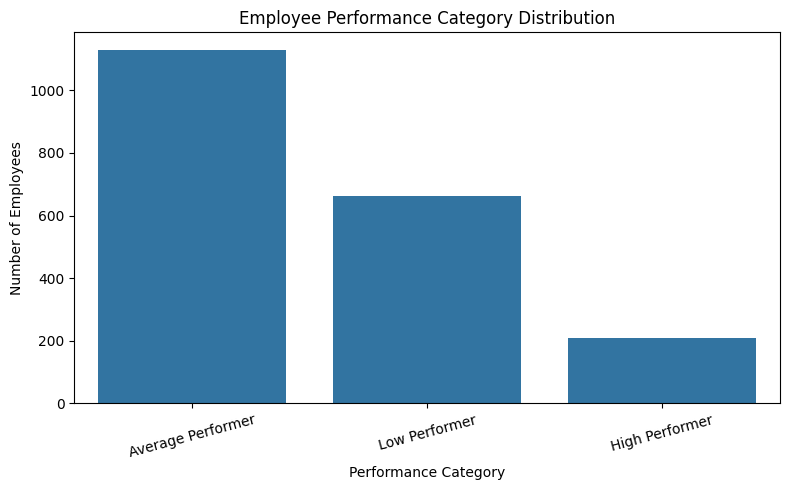

In [22]:
#Plot the target distribution:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Performance_Category",
    order=df["Performance_Category"].value_counts().index
)

plt.title("Employee Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Step 7: Explore relationships between features and performance
 

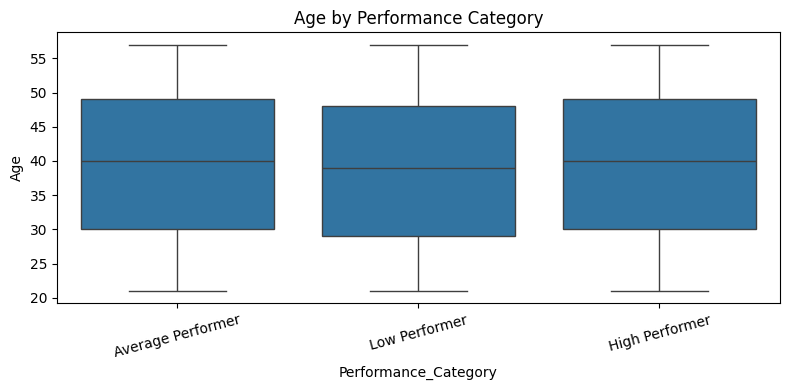

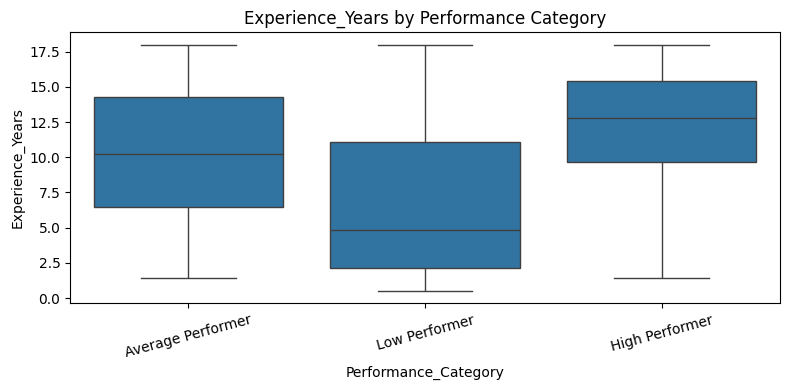

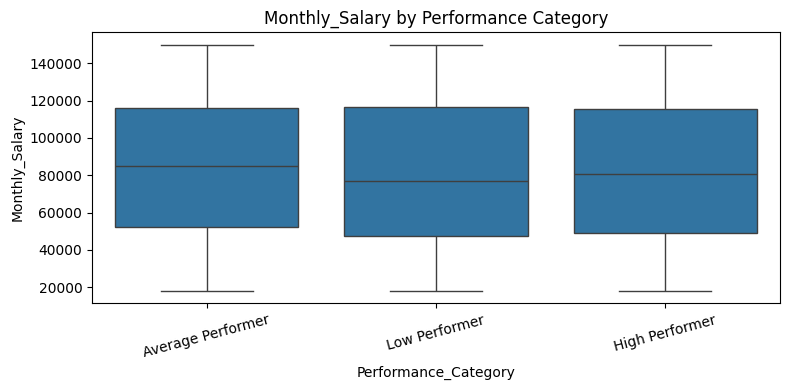

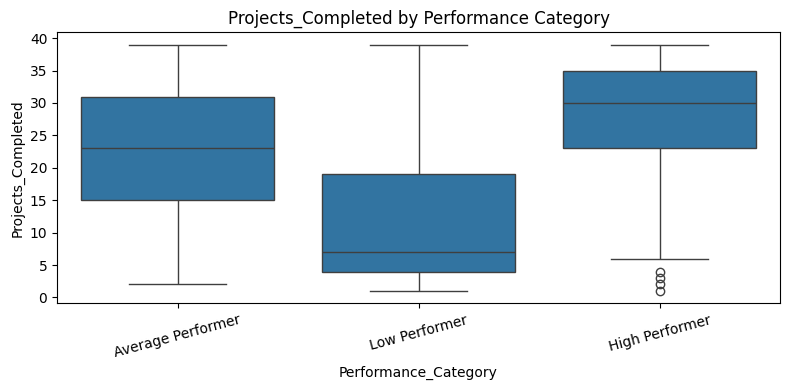

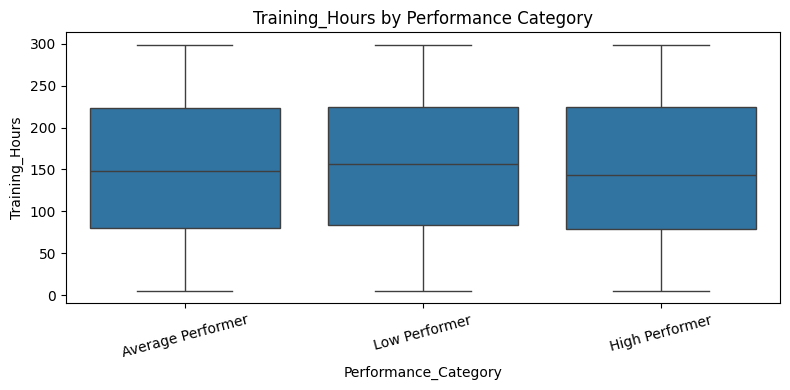

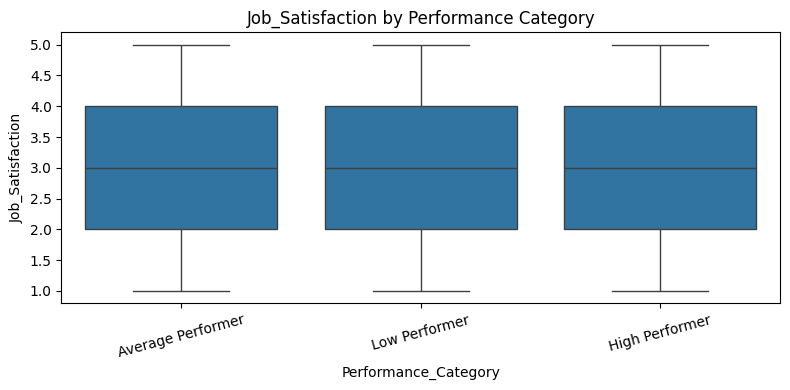

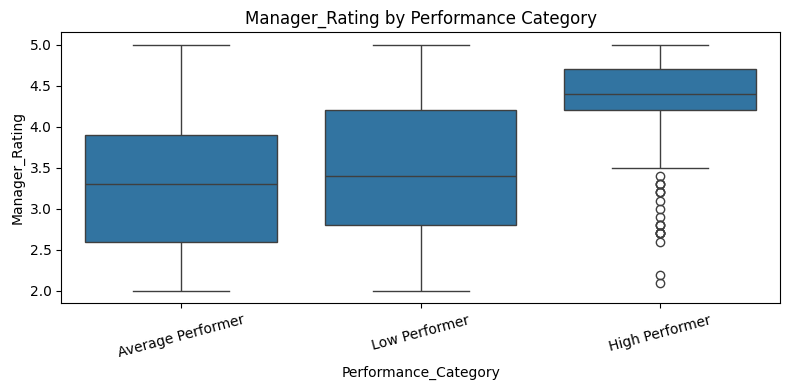

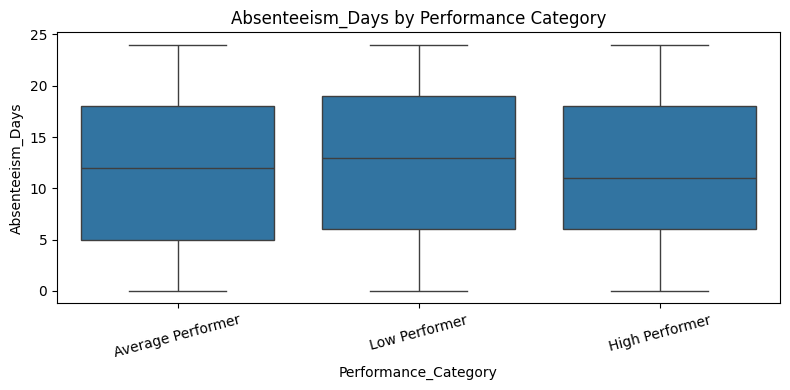

In [23]:
features = [
    "Age",
    "Experience_Years",
    "Monthly_Salary",
    "Projects_Completed",
    "Training_Hours",
    "Job_Satisfaction",
    "Manager_Rating",
    "Absenteeism_Days"
]

for column in features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="Performance_Category",
        y=column
    )

    plt.title(f"{column} by Performance Category")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

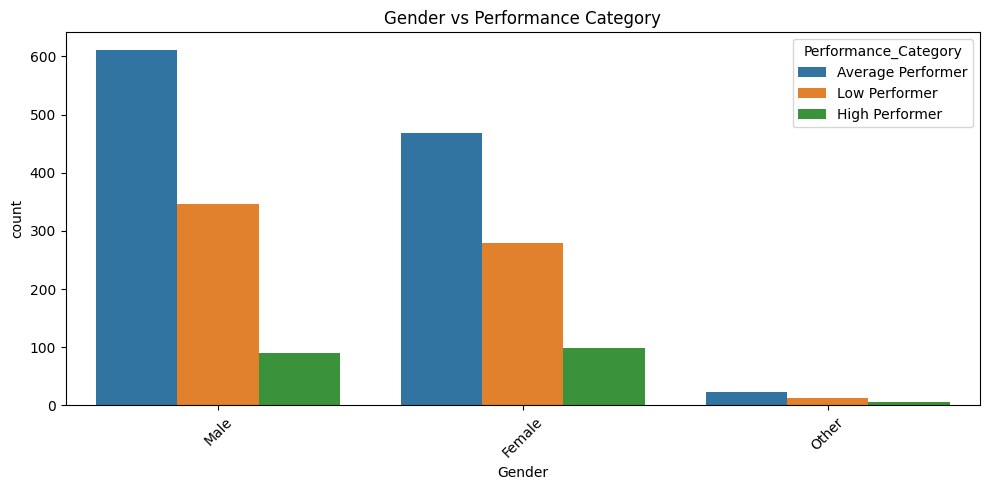

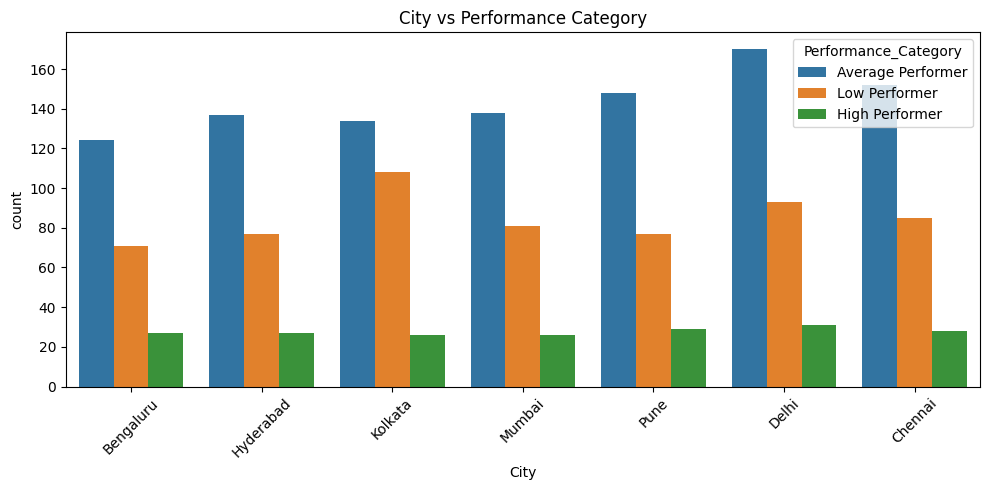

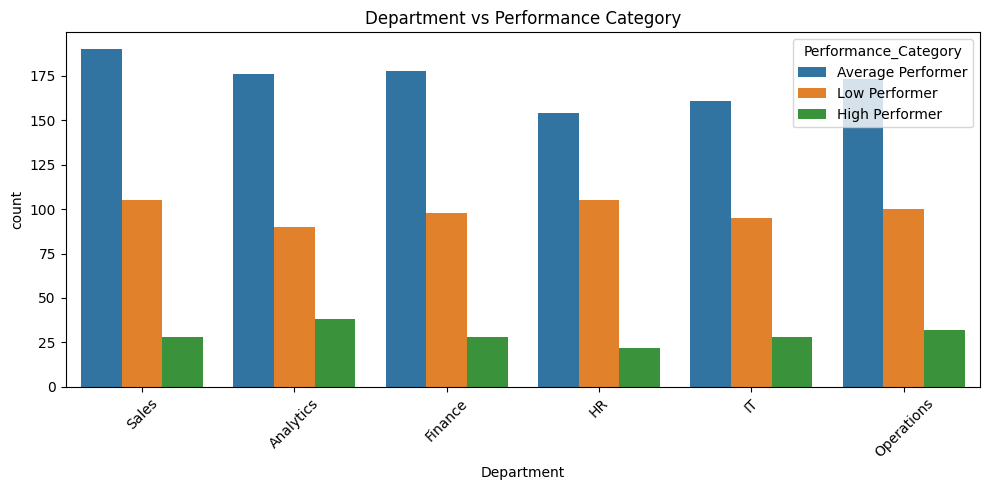

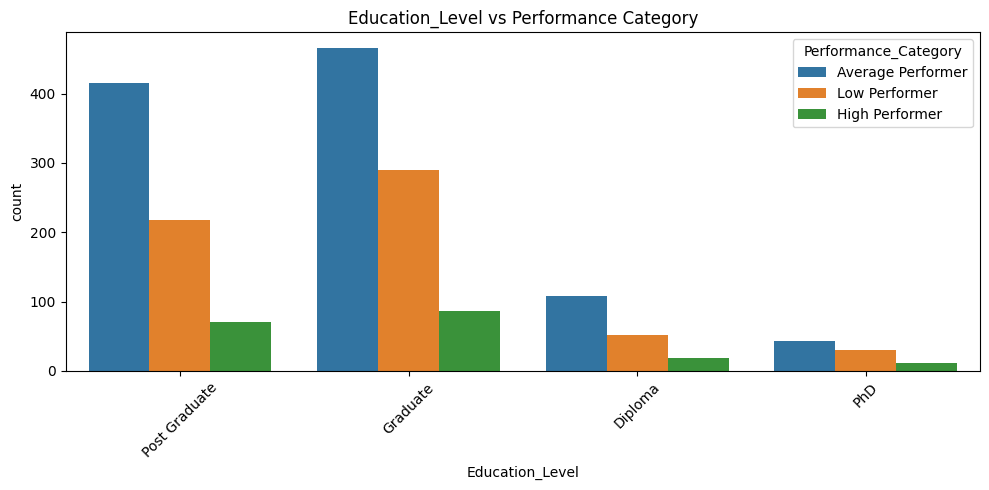

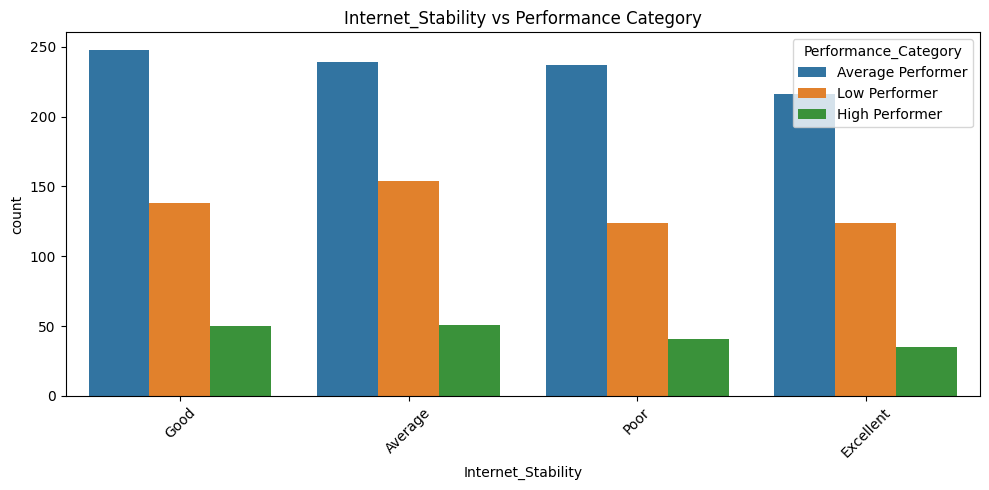

In [24]:
categorical_features_eda = [
    "Gender",
    "City",
    "Department",
    "Education_Level",
    "Internet_Stability"
]

for column in categorical_features_eda:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=column,
        hue="Performance_Category"
    )

    plt.title(f"{column} vs Performance Category")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

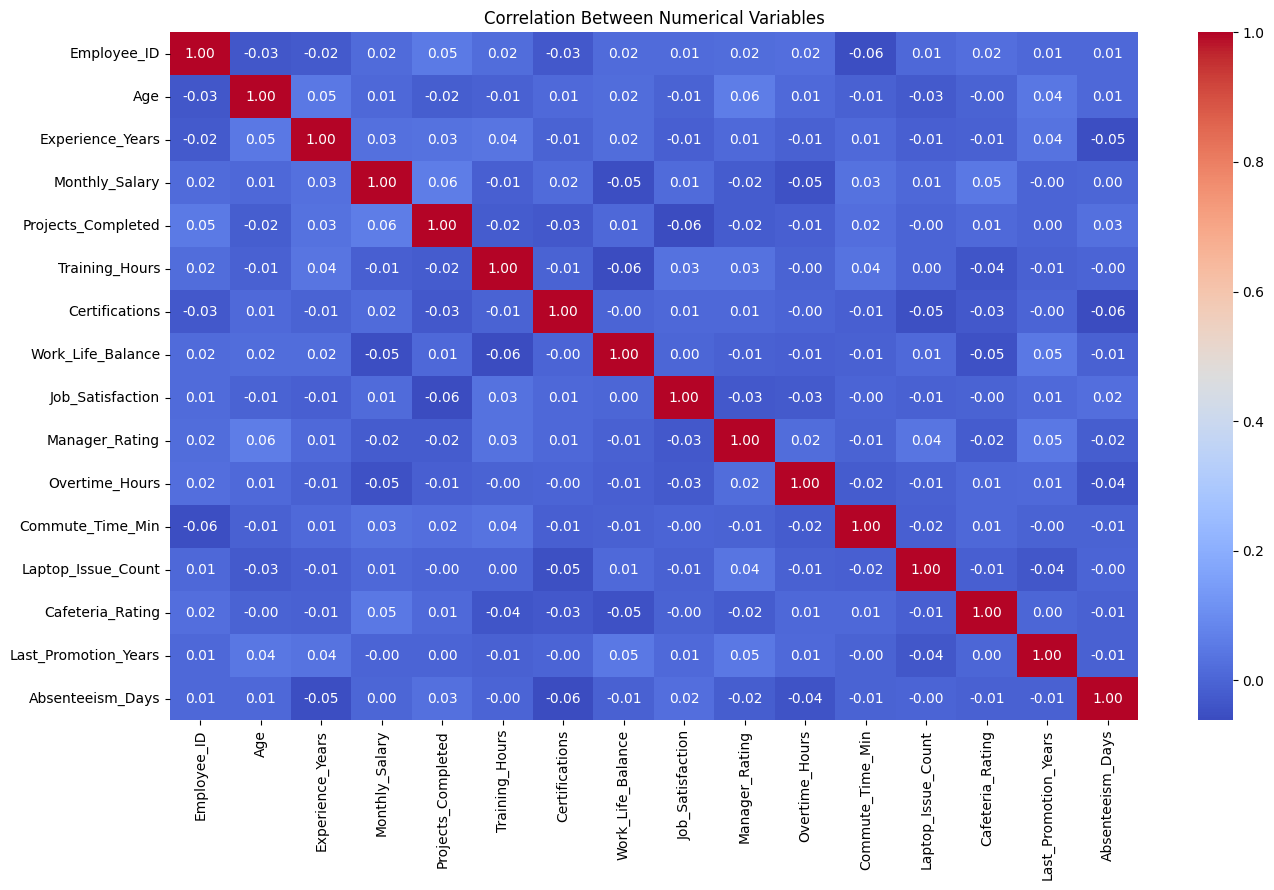

In [25]:
numeric_data = df.select_dtypes(include="number")

plt.figure(figsize=(14, 9))

sns.heatmap(
    numeric_data.corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

### Step 8: Separate input features and target

In [26]:
X = df.drop(
    columns=["Employee_ID", "Performance_Category"]
)

y = df["Performance_Category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (2000, 20)
y shape: (2000,)


,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days
0,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,1.0,2.0,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0
1,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,0.0,5.0,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0
2,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,1.0,3.0,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0
3,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,5.0,1.0,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0
4,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,0.0,NaN,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0


0    Average Performer
1        Low Performer
2    Average Performer
3    Average Performer
4        Low Performer
Name: Performance_Category, dtype: object

### Step 9: Split the dataset

In [27]:
#We will use 80% for training and 20% for validation.
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (1600, 20)
X_valid: (400, 20)
y_train: (1600,)
y_valid: (400,)


### Step 10: Build the missing-value preprocessing pipeline

In [28]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Last_Promotion_Years', 'Absenteeism_Days']
Categorical features: ['Gender', 'City', 'Education_Level', 'Department', 'Internet_Stability']
The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


In [29]:
numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

In [30]:
categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

### Step 11: Train and compare machine learning models

In [32]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

In [33]:
#Train each model with the same preprocessing pipeline:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict validation data
    y_pred = pipeline.predict(X_valid)

    # Calculate accuracy
    accuracy = accuracy_score(y_valid, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    trained_models[name] = pipeline

    print(name)
    print("Accuracy:", round(accuracy, 4))
    print("-" * 40)

Logistic Regression
Accuracy: 0.68
----------------------------------------
Random Forest
Accuracy: 0.8675
----------------------------------------
Extra Trees
Accuracy: 0.79
----------------------------------------


In [34]:
#Display the comparison table:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)

,Model,Accuracy
1,Random Forest,0.8675
2,Extra Trees,0.7900
0,Logistic Regression,0.6800


### Step 12: Evaluate the best model


In [36]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


In [38]:
#Predict validation records:
y_pred = best_model.predict(X_valid)

In [40]:
#Calculate accuracy:
accuracy = accuracy_score(y_valid, y_pred)

print("Validation Accuracy:", round(accuracy, 4))
print("Validation Accuracy (%):", round(accuracy * 100, 2))

Validation Accuracy: 0.8675
Validation Accuracy (%): 86.75


In [41]:
#Classification report
print(
    classification_report(
        y_valid,
        y_pred,
        zero_division=0
    )
)

                   precision    recall  f1-score   support

Average Performer       0.83      0.99      0.91       226
   High Performer       0.82      0.34      0.48        41
    Low Performer       0.96      0.82      0.88       133

         accuracy                           0.87       400
        macro avg       0.87      0.72      0.76       400
     weighted avg       0.87      0.87      0.85       400



### Step 13: Improve the model

In [42]:
balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_valid)

print(
    "Balanced Random Forest Accuracy:",
    round(accuracy_score(y_valid, balanced_pred), 4)
)

print(
    classification_report(
        y_valid,
        balanced_pred,
        zero_division=0
    )
)

Balanced Random Forest Accuracy: 0.8625
                   precision    recall  f1-score   support

Average Performer       0.82      0.99      0.90       226
   High Performer       0.86      0.29      0.44        41
    Low Performer       0.96      0.82      0.88       133

         accuracy                           0.86       400
        macro avg       0.88      0.70      0.74       400
     weighted avg       0.87      0.86      0.85       400



### Step 14: Train the final model on all training records

In [43]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        models[best_model_name]
    )
])

final_model.fit(X, y)

print("Final model trained successfully.")

Final model trained successfully.


### Step 15: Predict the test dataset

In [47]:
test = pd.read_csv(r"C:\Users\Avadhut\Downloads\perf_test.csv")

print("Test shape:", test.shape)
display(test.head())

Test shape: (500, 21)


,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days
0,12001,43.0,Female,Delhi,Graduate,Operations,NaN,110905.0,23.0,225.0,...,NaN,2.0,2.9,64.0,45.0,2.0,1.0,Excellent,3.3,1.0
1,12002,39.0,Male,Hyderabad,Post Graduate,HR,17.5,20977.0,26.0,86.0,...,3.0,5.0,2.8,65.0,80.0,4.0,4.0,Average,4.3,0.0
2,12003,NaN,Male,Delhi,Graduate,Finance,NaN,133650.0,NaN,246.0,...,1.0,NaN,NaN,25.0,111.0,6.0,2.0,Average,1.9,4.0
3,12004,25.0,NaN,Hyderabad,Graduate,Sales,14.1,72641.0,7.0,NaN,...,5.0,3.0,4.9,30.0,134.0,9.0,2.0,Average,4.1,23.0
4,12005,39.0,Male,NaN,Post Graduate,Analytics,NaN,132465.0,10.0,56.0,...,2.0,3.0,4.3,50.0,99.0,1.0,4.0,Poor,7.1,2.0


In [48]:
X_test = test.drop(
    columns=["Employee_ID"],
    errors="ignore"
)

X_test = X_test.reindex(
    columns=X.columns
)

In [49]:
test_predictions = final_model.predict(X_test)

print("Total predictions:", len(test_predictions))
print(pd.Series(test_predictions).value_counts())

Total predictions: 500
Average Performer    349
Low Performer        128
High Performer        23
Name: count, dtype: int64


### Step 16: Create the submission CSV file

In [50]:
submission = pd.DataFrame({
    "Employee_ID": test["Employee_ID"],
    "Performance_Category": test_predictions
})

print(submission.head())

print("Submission rows:", len(submission))
print("Test rows:", len(test))
print(
    "Missing predictions:",
    submission["Performance_Category"].isna().sum()
)

   Employee_ID Performance_Category
0        12001    Average Performer
1        12002    Average Performer
2        12003    Average Performer
3        12004        Low Performer
4        12005    Average Performer
Submission rows: 500
Test rows: 500
Missing predictions: 0


In [51]:
assert len(submission) == len(test)
assert submission["Employee_ID"].equals(test["Employee_ID"])
assert submission["Performance_Category"].notna().all()

submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created successfully!")

submission.csv created successfully!
